# Step 7: How accurate is it on real Nepal imagery?

Step 4 measured the model on Landslide4Sense patches. This notebook measures the **whole system on a real run** from the web app, in two ways:

**A. Your reviews (always available).** In the web app, open a run, click **Review next**, and mark each detection as *Real landslide* or *False alarm* by comparing the before and after images. This gives **precision**: of the things the system flagged, how many were real. Reviewing 30 or more detections gives a usable number.

**B. A landslide inventory (if you have one).** An inventory is a map of landslides drawn by researchers. With one, you can also measure **recall** (how many real landslides the system found) and check whether the false-alarm filters helped. Any GeoJSON, Shapefile, GeoPackage or KML of polygons or points works. Places to look:
- NASA's Cooperative Open Online Landslide Repository (COOLR): points, global
- Research papers on a specific event often share their inventory in a data repository (Zenodo, Figshare). For example, the September 2024 central Nepal event has been studied in the journal *Landslides*.
- Or draw your own: trace 20–30 obvious scars as polygons in QGIS or on geojson.io and save the file.

No extra installs needed. It uses the same libraries as Step 5.

In [7]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import box

ROOT = Path.home() / "geoai"
RUNS_DIR = ROOT / "runs"

runs = []
for p in sorted(RUNS_DIR.glob("*/run.json")):
    r = json.loads(p.read_text())
    if r["status"] == "done":
        reviews = RUNS_DIR / r["id"] / "reviews.json"
        r["n_reviewed"] = len(json.loads(reviews.read_text())) if reviews.exists() else 0
        runs.append(r)
runs.sort(key=lambda r: r["created"], reverse=True)

print(f"{'run id':<24}{'name':<32}{'after image':<13}{'found':>6}{'reviewed':>10}")
for r in runs:
    s = r["summary"]
    print(f"{r['id']:<24}{r['name'][:30]:<32}{s['after_date']:<13}{s['num_new_landslides']:>6}{r['n_reviewed']:>10}")

run id                  name                            after image   found  reviewed
20261014-042221-d898    Jhyaple Khola (Sep 2024)        2024-12-15       91        30
20261014-042113-232d    Jhyaple Khola (Sep 2024)        2024-12-15      104        31
20261013-104849-f63e    Jhyaple Khola (Sep 2024)        2024-12-15       10         1
20261013-001127-7e8d    Melamchi (Jun 2021)             2021-12-01       16         1
notebook                Notebook run (Step 5)           2024-12-15       15         0


## Pick a run
By default this uses the run you've reviewed the most. To use a different one, paste its id from the list above.

In [8]:
RUN_ID = max(runs, key=lambda r: (r["n_reviewed"], r["created"]))["id"] if runs else None
RUN_ID = "20261014-042113-232d"

run = json.loads((RUNS_DIR / RUN_ID / "run.json").read_text())
summary = run["summary"]
run_dir = RUNS_DIR / RUN_ID

def read_geo(name):
    path = run_dir / name
    if not path.exists() or not json.loads(path.read_text())["features"]:
        return gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")
    return gpd.read_file(path)

kept = read_geo("landslides.geojson")
removed = read_geo("removed.geojson")
reviews = json.loads((run_dir / "reviews.json").read_text()) if (run_dir / "reviews.json").exists() else {}
if len(kept) and "fid" not in kept.columns:
    kept["fid"] = range(1, len(kept) + 1)
kept["review"] = [reviews.get(str(f)) for f in kept["fid"]] if len(kept) else []

print(f"Run: {run['name']}  ({summary['before_date']} -> {summary['after_date']})")
print(f"Model: {summary.get('model_label', 'v1')} | threshold {summary['threshold']}")
print(f"Detections kept: {len(kept)} | removed by filters: {len(removed)} | reviewed: {len(reviews)}")

Run: Jhyaple Khola (Sep 2024)  (2023-10-22 -> 2024-12-15)
Model: v2: U-Net + pretrained ResNet34 | threshold 0.85
Detections kept: 104 | removed by filters: 10 | reviewed: 31


## A. Precision from your reviews
Precision = real ÷ (real + false alarms). The **95% interval** shows how sure the number is. With few reviews it's wide, and it narrows as you review more. This uses the Wilson score interval, a standard method for proportions.

In [9]:
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return (centre - half, centre + half)

reviewed = kept[kept["review"].notna()] if len(kept) else kept
n_real = int((reviewed["review"] == "real").sum()) if len(reviewed) else 0
n_false = int((reviewed["review"] == "false").sum()) if len(reviewed) else 0
n_rev = n_real + n_false

if n_rev == 0:
    print("No reviews yet. In the web app, open this run, click 'Review next', and mark detections.")
else:
    lo, hi = wilson(n_real, n_rev)
    print(f"Reviewed {n_rev} of {len(kept)} detections: {n_real} real, {n_false} false alarms")
    print(f"Precision: {n_real / n_rev:.0%}  (95% interval {lo:.0%} – {hi:.0%})")
    if n_rev < 30:
        print("Tip: review at least 30 for a reliable number.")

Reviewed 31 of 104 detections: 29 real, 2 false alarms
Precision: 94%  (95% interval 79% – 98%)


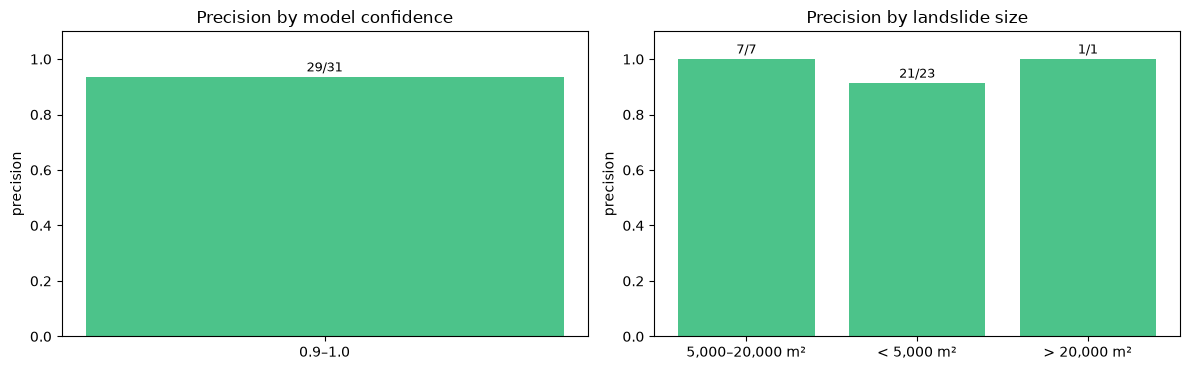

If precision is much higher at high confidence, raising the threshold would cut false alarms.


In [10]:
if n_rev:
    rv = reviewed.copy()
    rv["conf_bin"] = np.clip(np.floor(rv["max_prob"] * 10) / 10, 0, 0.9)
    rv["size_bin"] = np.where(rv["area_m2"] < 5000, "< 5,000 m²", np.where(rv["area_m2"] < 20000, "5,000–20,000 m²", "> 20,000 m²"))

    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
    for ax, col, title in [(axes[0], "conf_bin", "Precision by model confidence"), (axes[1], "size_bin", "Precision by landslide size")]:
        g = rv.groupby(col)["review"].agg(real=lambda s: (s == "real").sum(), total="count")
        labels = [f"{x:.1f}–{x + 0.1:.1f}" if col == "conf_bin" else x for x in g.index]
        ax.bar(labels, g["real"] / g["total"], color="#4cc38a")
        for i, (r_, t_) in enumerate(zip(g["real"], g["total"])):
            ax.text(i, r_ / t_ + 0.02, f"{r_}/{t_}", ha="center", fontsize=9)
        ax.set_ylim(0, 1.1); ax.set_title(title); ax.set_ylabel("precision")
    plt.tight_layout(); plt.show()
    print("If precision is much higher at high confidence, raising the threshold would cut false alarms.")

## B. Compare against a landslide inventory
Set `INVENTORY_PATH` to your file. Leave it as `None` to skip this part.

How matching works (object-based, the usual way to score landslide maps):
- A **detection** counts as correct if it overlaps any inventory landslide.
- An **inventory landslide** counts as found if any detection overlaps it.
- Points are turned into small circles first (`POINT_BUFFER_M`), because point inventories mark only roughly where a landslide is.

In [11]:
INVENTORY_PATH = None          # e.g. Path.home() / "Downloads" / "nepal_2024_landslides.geojson"
POINT_BUFFER_M = 50

In [12]:
def utm_crs(lat, lon):
    return f"EPSG:{(32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1}"

def match(detections, inventory):
    if len(detections) == 0 or len(inventory) == 0:
        return np.zeros(len(detections), bool), np.zeros(len(inventory), bool)
    det_hit = detections.geometry.apply(lambda g: inventory.intersects(g).any()).to_numpy()
    inv_found = inventory.geometry.apply(lambda g: detections.intersects(g).any()).to_numpy()
    return det_hit, inv_found

def report(name, detections, inventory):
    det_hit, inv_found = match(detections, inventory)
    p = det_hit.mean() if len(detections) else np.nan
    r = inv_found.mean() if len(inventory) else np.nan
    f1 = 2 * p * r / (p + r) if p + r > 0 else 0.0
    row = dict(setting=name, detections=len(detections), correct=int(det_hit.sum()),
               inventory=len(inventory), found=int(inv_found.sum()), precision=p, recall=r, f1=f1)
    if len(detections) and len(inventory) and (inventory.geom_type.isin(["Polygon", "MultiPolygon"])).all():
        d, t = detections.union_all(), inventory.union_all()
        row["iou"] = d.intersection(t).area / d.union(t).area
    return row, det_hit, inv_found

if INVENTORY_PATH is None:
    print("No inventory set, so skipping part B.")
else:
    lat, lon = summary["center"]
    crs = utm_crs(lat, lon)
    w, s, e, n = summary["bbox"]
    area = gpd.GeoSeries([box(w, s, e, n)], crs="EPSG:4326").to_crs(crs).iloc[0]

    inv = gpd.read_file(INVENTORY_PATH)
    inv = (inv.set_crs("EPSG:4326") if inv.crs is None else inv).to_crs(crs)
    points = inv.geom_type.isin(["Point", "MultiPoint"])
    inv.loc[points, "geometry"] = inv.loc[points].buffer(POINT_BUFFER_M)
    inv = inv[inv.intersects(area)].reset_index(drop=True)
    print(f"Inventory landslides inside this run's area: {len(inv)}")

    kept_u = kept.to_crs(crs) if len(kept) else kept
    all_u = gpd.GeoDataFrame(geometry=list(kept_u.geometry) + list(removed.to_crs(crs).geometry if len(removed) else []), crs=crs)

    rows = []
    row, det_hit, inv_found = report("with filters (what the app shows)", kept_u, inv); rows.append(row)
    rows.append(report("without filters", all_u, inv)[0])

    print(f"\n{'setting':<36}{'det':>5}{'ok':>5}{'inv':>6}{'found':>7}{'precision':>11}{'recall':>8}{'F1':>7}{'IoU':>7}")
    for r_ in rows:
        print(f"{r_['setting']:<36}{r_['detections']:>5}{r_['correct']:>5}{r_['inventory']:>6}{r_['found']:>7}"
              f"{r_['precision']:>11.2f}{r_['recall']:>8.2f}{r_['f1']:>7.2f}{r_.get('iou', float('nan')):>7.2f}")

    if len(removed):
        removed_u = removed.to_crs(crs)
        rm_hit, _ = match(removed_u, inv)
        print(f"\nOf {len(removed_u)} detections the filters removed, {int(rm_hit.sum())} overlapped a real landslide.")
        print("A good filter removes many false alarms and few real landslides.")

    fig, ax = plt.subplots(figsize=(8, 8))
    gpd.GeoSeries([area], crs=crs).boundary.plot(ax=ax, color="#999", linestyle="--")
    if len(inv):
        inv[inv_found].plot(ax=ax, color="#4c8bf5", alpha=0.5)
        inv[~inv_found].plot(ax=ax, color="#4c8bf5", alpha=0.15, edgecolor="#4c8bf5")
    if len(kept_u):
        kept_u[det_hit].boundary.plot(ax=ax, color="#2ca05a", linewidth=1.5)
        kept_u[~det_hit].boundary.plot(ax=ax, color="#e0442b", linewidth=1.5)
    ax.set_title("Blue: inventory (faint = missed)   Green: correct detection   Red: false alarm")
    ax.set_axis_off(); plt.tight_layout(); plt.show()

No inventory set, so skipping part B.


## How to write this up
- **Precision from reviews** with its 95% interval, and how many you reviewed.
- If you had an inventory: **precision, recall and F1**, with and without the filters. This shows whether the filters did their job.
- **Compare with Step 4.** Real-world scores are usually lower than validation scores. The gap is the domain-shift effect, and explaining it shows you understand the limits of your model.
- A few example detections: a clear hit, a false alarm (and why it happened), and a miss.